# NLP MIDTERM PROJECT: AUTHOR DETECTION USING NLP

**SERHAT TAY / 220709054**

# Project: Who Wrote This? Authorship Attribution using NLP
**Objective**

The goal is to build a machine learning model that can identify the author of a given text based on their writing style. We will use the 30Columnist dataset, preprocess the text, extract TF-IDF features, and train a classifier.


---



# **Part A: Data Preparation**
# 1. Import Libraries

In [ ]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Machine Learning Libraries
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Visual setup
%matplotlib inline
sns.set(style="whitegrid")

# Download necessary NLTK data
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab') # Sometimes needed for newer versions
print("Libraries Imported.")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Libraries Imported.


# 2. Download and Unzip Dataset
Download and unzipping steps of the file:

In [ ]:
# Download the dataset
!gdown https://drive.google.com/uc?id=120-9PFzIvWy1SVHpTiOO6_7vOyMpXZEy

# Unzip the file
!unzip -q /content/30Columnists.zip -d /content
print("Dataset downloaded and extracted.")

Downloading...
From (original): https://drive.google.com/uc?id=120-9PFzIvWy1SVHpTiOO6_7vOyMpXZEy
From (redirected): https://drive.google.com/uc?id=120-9PFzIvWy1SVHpTiOO6_7vOyMpXZEy&confirm=t&uuid=028bf8ad-2c44-4044-9b04-3e8c0169f4f7
To: /content/30Columnists.zip
100% 7.38M/7.38M [00:00<00:00, 95.5MB/s]
Dataset downloaded and extracted.


# 3. Load Data into DataFrame
We will read the raw text files. The dataset structure is folders named by Author ID containing .txt files.
Note: We use 'cp1254' encoding as per the reference notebook to handle special characters.

In [ ]:
data_path = "/content/30Columnists/raw_texts"
dataset = []

# Get list of authors (folder names)
labels = [d for d in os.listdir(data_path) if os.path.isdir(os.path.join(data_path, d))]
labels.sort(key=lambda e: int(e)) # Sort numerically

print(f"Found {len(labels)} Authors.")

# Iterate through author folders and read text files
for author in labels:
    author_dir = os.path.join(data_path, author)
    for file in os.listdir(author_dir):
        if file.endswith('.txt'):
            file_path = os.path.join(author_dir, file)
            try:
                with open(file_path, 'rb') as f:
                    # Decode using cp1254 as suggested in reference
                    text = f.read().decode('cp1254').replace('\n', ' ').replace('\r', '')

                    dataset.append({
                        'text': text,
                        'author': author
                    })
            except Exception as e:
                print(f"Error reading {file}: {e}")

# Convert to Pandas DataFrame
df = pd.DataFrame(dataset)

# Shuffle the dataframe
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Total documents loaded: {len(df)}")
df.head()

Found 30 Authors.
Total documents loaded: 1500


,text,author
0,"For many adults, the first sign of Spring mean...",23
1,SOUTHAMPTON ushered Wolves towards the Premier...,28
2,Starting the day on an egg could keep your blo...,9
3,"Rushing into IVF may do more harm than good, a...",9
4,"A fortnight tomorrow, Gordon Brown will make h...",10


# 4. Text Cleaning and Preprocessing
**We will create a function to:**



1.   Lowercase text
2.   Remove special characters and digits.
3.   Remove stopwords (common words like "the", "is" that don't carry stylistic weight).



In [ ]:
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    # 1. Lowercase
    text = text.lower()

    # 2. Remove non-alphabetic characters (punctuation/numbers) using Regex
    text = re.sub(r'[^a-z\s]', '', text)

    # 3. Tokenize
    tokens = word_tokenize(text)

    # 4. Remove Stopwords and short words
    filtered_tokens = [w for w in tokens if w not in stop_words and len(w) > 2]

    # Join back to string
    return " ".join(filtered_tokens)

# Apply preprocessing
print("Preprocessing text... this might take a moment.")
df['cleaned_text'] = df['text'].apply(preprocess_text)

# View comparison
print(df[['text', 'cleaned_text']].head())

Preprocessing text... this might take a moment.
                                                text  \
0  For many adults, the first sign of Spring mean...   
1  SOUTHAMPTON ushered Wolves towards the Premier...   
2  Starting the day on an egg could keep your blo...   
3  Rushing into IVF may do more harm than good, a...   
4  A fortnight tomorrow, Gordon Brown will make h...   

                                        cleaned_text  
0  many adults first sign spring means allergies ...  
1  southampton ushered wolves towards premier lea...  
2  starting day egg could keep blood pressure che...  
3  rushing ivf may harm good leading fertility ex...  
4  fortnight tomorrow gordon brown make leaders s...  




---
# Part B: Feature Engineering

We will use **TF-IDF (Term Frequency-Inverse Document Frequency)**. This technique highlights words that are unique to specific documents (or authors) while downplaying words that appear everywhere.

We will extract **N-Grams** (combinations of 1 to 2 words) to capture phrases, not just individual words.


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack # Import hstack to combine sparse matrices

# Initialize TF-IDF Vectorizer for word n-grams
# ngram_range=(1, 2) means we take unigrams (words) and bigrams (two-word phrases)
tfidf_word = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))

# Initialize TF-IDF Vectorizer for character n-grams
# analyzer='char_wb' for character n-grams within word boundaries
# ngram_range=(2, 4) is a common choice for character n-grams
tfidf_char = TfidfVectorizer(max_features=5000, analyzer='char_wb', ngram_range=(2, 4))

# Create the Feature Matrix (X) and Target Vector (y)

# Fit and transform for word n-grams
X_word = tfidf_word.fit_transform(df['cleaned_text'])

# Fit and transform for character n-grams
X_char = tfidf_char.fit_transform(df['cleaned_text'])

# Combine the feature matrices horizontally
X = hstack([X_word, X_char])
y = df['author']

print(f"Feature Matrix Shape: {X.shape}")
# (Number of docs, Number of features)

Feature Matrix Shape: (1500, 10000)




---
# Part C: Modeling
**1. Train/Test Split**

We split the data: 80% for training the model, 20% for testing it.



In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")

Training samples: 1200
Testing samples: 300



**2. Train Model (Logistic Regression)**

Logistic Regression is excellent for text classification because it works well with high-dimensional sparse data (like TF-IDF).

In [ ]:
# Initialize model
model = LogisticRegression(max_iter=1000, multi_class='ovr')

# Train
print("Training model...")
model.fit(X_train, y_train)
print("Training complete.")

Training model...


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


Training complete.


**3. Evaluate Model**

In [ ]:
# Make predictions
y_pred = model.predict(X_test)

# Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.2%}")

# Detailed Classification Report
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Model Accuracy: 86.00%

Classification Report:

              precision    recall  f1-score   support

           1       1.00      0.90      0.95        10
          10       0.69      0.90      0.78        10
          11       0.88      0.70      0.78        10
          12       0.71      1.00      0.83        10
          13       0.71      1.00      0.83        10
          14       1.00      0.80      0.89        10
          15       1.00      0.70      0.82        10
          16       1.00      0.80      0.89        10
          17       1.00      1.00      1.00        10
          18       1.00      0.90      0.95        10
          19       0.69      0.90      0.78        10
           2       0.75      0.90      0.82        10
          20       0.83      1.00      0.91        10
          21       0.89      0.80      0.84        10
          22       1.00      1.00      1.00        10
          23       0.83      1.00      0.91        10
          24       0.75      0.90



---
# Part D: Analysis
**1. Confusion Matrix**

Visualizing which authors are getting confused with each other.


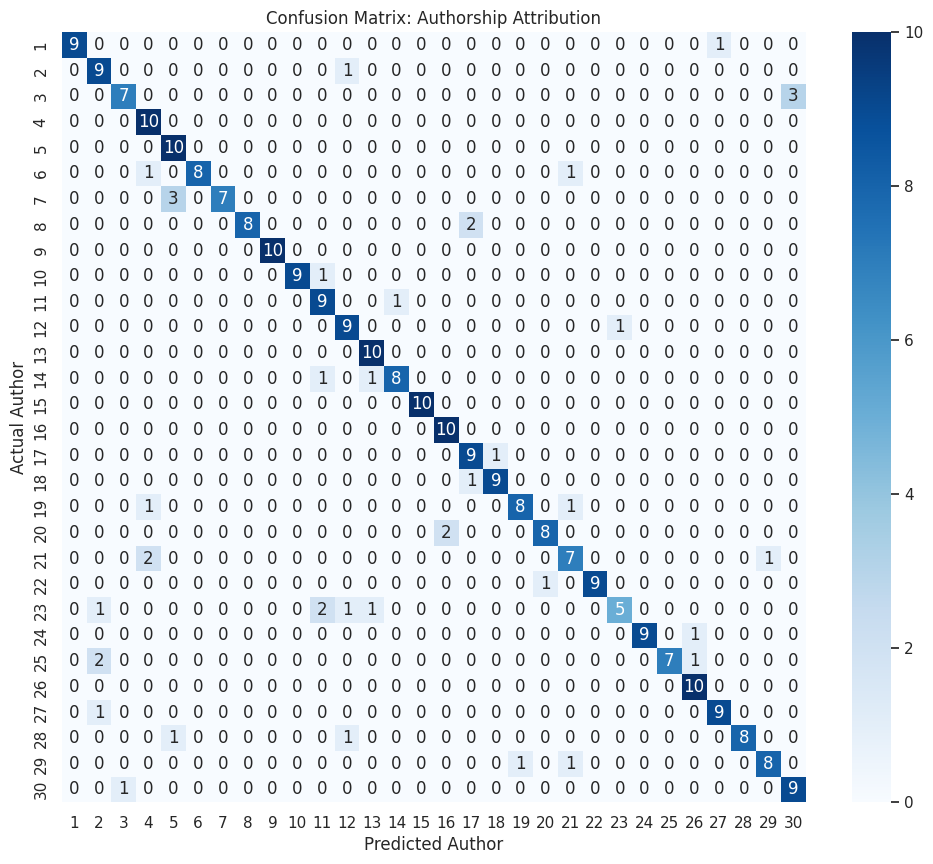

In [ ]:
plt.figure(figsize=(12, 10))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted Author')
plt.ylabel('Actual Author')
plt.title('Confusion Matrix: Authorship Attribution')
plt.show()

**2. Feature Importance (Top Words per Author)**

Since we used a linear model, we can look at the coefficients to see which words are most indicative for each author.

In [ ]:
def print_top_words(model, feature_names, n_top_words=10):
    # Loop through every author class
    for i, class_label in enumerate(model.classes_):
        # Get indices of the top positive coefficients
        # Use try-except to handle cases where coef_ might be empty or invalid
        if model.coef_[i].size == 0:
            print(f"Author {class_label}: No features for this author.")
            continue

        top_ids = np.argsort(model.coef_[i])[-n_top_words:]

        # Map indices to words
        # Ensure feature_names is accessible and valid
        top_words = [feature_names[j] for j in top_ids if j < len(feature_names)]

        print(f"Author {class_label}: {', '.join(top_words)}")

# Get feature names from TF-IDF
# Now we have two vectorizers, tfidf_word and tfidf_char
# We need to combine their feature names in the correct order as they were combined in X
# Ensure tfidf_word and tfidf_char are defined and fitted from the previous cell
if 'tfidf_word' in locals() and 'tfidf_char' in locals() and tfidf_word.vocabulary_ and tfidf_char.vocabulary_:
    feature_names_word = tfidf_word.get_feature_names_out()
    feature_names_char = tfidf_char.get_feature_names_out()
    feature_names = np.concatenate([feature_names_word, feature_names_char])
    print("Top 10 most indicative words/phrases for each author:\n")
    print_top_words(model, feature_names)
else:
    print("Error: TF-IDF vectorizers (tfidf_word or tfidf_char) are not fitted or defined.")
    print("Please ensure previous cells for feature engineering are executed successfully.")

NotFittedError: Vocabulary not fitted or provided

**3. Testing User's Input**

Let's try the model on a string given by an user to see who (which author) it predicts.

In [ ]:
def predict_author(text):
    # Preprocess
    cleaned = preprocess_text(text)
    # Vectorize
    vec = tfidf.transform([cleaned])
    # Predict
    prediction = model.predict(vec)[0]
    return prediction

# Example usage (using a snippet from the dataset or new text)
sample_text = input("Enter the text you want to predict the author for: ")
predicted_author = predict_author(sample_text)

print(f"Input Text: '{sample_text}'")
print(f"Predicted Author ID: {predicted_author}")